# Notebook 5: Model Prediction Demonstration

## 5.1 Introduction

This notebook demonstrates the predictive capability of the machine learning model developed in Notebook 4 for the shoe manufacturing division of Ceylon Leather Products Manufacturers Ltd (DI Leather).

The selected Voting Ensemble model is loaded from the saved model file and used to predict actual production quantity (`actual_qty`) for unseen test records.

The notebook focuses on demonstrating model predictions, comparing predicted and actual production quantities, examining prediction errors, and interpreting the results.

This notebook covers **Phase 1: Predictive Analytics** only. Prescriptive analytics and operational resource optimisation are outside the scope of this notebook.

## 5.1.1 Objectives

The objectives of this notebook are:

1. Load the saved Voting Ensemble model from Notebook 4.
2. Load the processed production dataset and reproduce the chronological train-test split.
3. Generate predictions for the held-out test records.
4. Compare predicted actual production quantities with observed quantities.
5. Evaluate predictions using R², MAE, and RMSE.
6. Visualise prediction performance and examine individual prediction errors.

The target variable remains `actual_qty`, representing actual production quantity.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 5.3 Loading the Trained Model

Notebook 4 selected the Voting Ensemble with inverse cross-validation MAE weights as the final model.

The ensemble combines the MLP Regressor, XGBoost, and Support Vector Regression models. The complete fitted pipeline, including preprocessing and the ensemble, was saved as `production_model.joblib`.

The saved pipeline is loaded directly so that the same preprocessing and modelling steps are applied during prediction. The model is not retrained in this notebook.

In [22]:
# ============================================================
# 5.3 Loading the Trained Model
# Load the training-only model for held-out test evaluation
# ============================================================

from pathlib import Path
import joblib

# Step 1: Locate the project root
possible_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd().parent.parent
]

project_root = None

for folder in possible_roots:
    model_file = (
        folder / "models" / "production_model_evaluation.joblib"
    )

    data_file = (
        folder / "data" / "processed" / "final_features.csv"
    )

    if model_file.exists() and data_file.exists():
        project_root = folder
        break

# Step 2: Check whether the project root was found
if project_root is None:
    raise FileNotFoundError(
        "Project root not found. Check that the notebook is inside "
        "the notebooks folder and that the models and data folders exist."
    )

# Step 3: Define the evaluation model path
model_path = (
    project_root
    / "models"
    / "production_model_evaluation.joblib"
)

# Step 4: Check whether the evaluation model exists
if not model_path.exists():
    raise FileNotFoundError(
        f"Evaluation model not found at: {model_path}\n"
        "Run Notebook 4 and save the training-only evaluation model first."
    )

# Step 5: Load the model
production_model = joblib.load(model_path)

# Step 6: Display confirmation
print("Evaluation model loaded successfully.")
print("Project root:", project_root)
print("Model path:", model_path.resolve())
print("Model type:", type(production_model).__name__)

Evaluation model loaded successfully.
Project root: c:\Production-DI Leather\production-DI
Model path: C:\Production-DI Leather\production-DI\models\production_model_evaluation.joblib
Model type: Pipeline


## 5.4 Loading the Processed Dataset

The feature-engineered dataset created in the earlier notebooks is used for the prediction demonstration.

The dataset contains 9,495 records and 18 columns, including 16 model input features, the date key, and the target variable `actual_qty`.

The date key is used to maintain chronological order but is not supplied to the model. The target variable is separated from the input features to prevent target leakage.

In [23]:
features_path = (
    project_root / "data" / "processed" / "final_features.csv"
)

df = pd.read_csv(features_path)

date_column = "week_start_date"
target_column = "actual_qty"

if date_column not in df.columns:
    raise ValueError(f"Missing required column: {date_column}")

if target_column not in df.columns:
    raise ValueError(f"Missing required column: {target_column}")

df[date_column] = pd.to_datetime(
    df[date_column],
    errors="coerce"
)

df = (
    df.dropna(subset=[date_column, target_column])
      .sort_values(date_column)
      .reset_index(drop=True)
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("First date:", df[date_column].min())
print("Last date:", df[date_column].max())

display(df.head())

Dataset loaded successfully.
Dataset shape: (9495, 18)
First date: 2022-04-18 00:00:00
Last date: 2026-03-30 00:00:00


,week_start_date,financial_month,week_no,week_of_month,factory_unit,product_family,item_name,size_id,grade,rate,no_of_workers,working_hours,machine_count,bottleneck_flag,order_category,machine_worker_ratio,avg_hours_per_worker,actual_qty
0,2022-04-18,Apr,3,3,Factory Unit 01,Ladies,BINOLI (VAST) - BROWN,12,A,4363.35,15,647.82,5,1,Others,0.333333,43.188000,38
1,2022-04-18,Apr,3,3,Factory Unit 01,Gents,JORDY - L - BLACK,11,B,2982.20,27,1134.10,6,0,Others,0.222222,42.003704,58
2,2022-04-18,Apr,3,3,Factory Unit 01,Ladies,BINOLI - L - GREEN,9,A,7003.71,15,673.07,3,0,Others,0.200000,44.871333,44
3,2022-04-18,Apr,3,3,Factory Unit 01,Gents,BOOT HIGH LEG - BLACK,13,A,4676.91,11,550.89,3,0,Forces/Police,0.272727,50.080909,31
4,2022-04-18,Apr,3,3,Factory Unit 01,Gents,BOOT HIGH LEG - L - BLACK,13,A,3803.13,18,813.02,5,1,Forces/Police,0.277778,45.167778,36


## 5.4.1 Reproducing the Chronological Train-Test Split

A chronological split is used to preserve the time order of the production records. Earlier records are used for training, while later records are reserved for testing.

This approach reflects the intended forecasting setting, where historical observations are used to predict production in a later period.

The same 80:20 chronological split used in Notebook 4 is reproduced so that the prediction demonstration uses the held-out test period rather than records used to fit the final saved model.

In [24]:
# Reproduce the chronological 80:20 split used in Notebook 4.
split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

X_test = test_df.drop(
    columns=[date_column, target_column]
)

y_test = test_df[target_column]

# Align columns with those expected by the saved model.
if hasattr(production_model, "feature_names_in_"):
    expected_features = list(production_model.feature_names_in_)

    missing_features = [
        col for col in expected_features
        if col not in X_test.columns
    ]

    if missing_features:
        raise ValueError(
            f"Missing model input features: {missing_features}"
        )

    X_test = X_test[expected_features]

print("Chronological split completed.")
print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print(
    "Training period:",
    train_df[date_column].min(),
    "to",
    train_df[date_column].max()
)

print(
    "Testing period:",
    test_df[date_column].min(),
    "to",
    test_df[date_column].max()
)

print("Number of model input features:", X_test.shape[1])

Chronological split completed.
Training records: 7596
Testing records: 1899
Training period: 2022-04-18 00:00:00 to 2025-03-24 00:00:00
Testing period: 2025-03-24 00:00:00 to 2026-03-30 00:00:00
Number of model input features: 16


## 5.5 Predicting Actual Production Quantity

The saved Voting Ensemble is applied to the held-out test records to predict actual production quantity (`actual_qty`).

The observed production quantities are retained for comparison with the predictions. The difference between observed and predicted quantities is used to calculate the prediction error.

A positive prediction error indicates that actual production exceeded the predicted quantity. A negative prediction error indicates that actual production was lower than predicted.

In [25]:
# Generate predictions using the saved model.
y_pred = production_model.predict(X_test)

prediction_results = test_df[
    [date_column, target_column]
].copy()

prediction_results["predicted_actual_qty"] = y_pred

prediction_results["prediction_error"] = (
    prediction_results[target_column]
    - prediction_results["predicted_actual_qty"]
)

prediction_results["absolute_error"] = (
    prediction_results["prediction_error"].abs()
)

display(prediction_results.head(10))

,week_start_date,actual_qty,predicted_actual_qty,prediction_error,absolute_error
7596,2025-03-24,29,25.173223,3.826777,3.826777
7597,2025-03-24,53,50.485873,2.514127,2.514127
7598,2025-03-24,37,30.174362,6.825638,6.825638
7599,2025-03-24,45,49.432021,-4.432021,4.432021
7600,2025-03-24,36,28.879948,7.120052,7.120052
7601,2025-03-24,22,26.905387,-4.905387,4.905387
7602,2025-03-24,31,35.468569,-4.468569,4.468569
7603,2025-03-24,45,42.296455,2.703545,2.703545
7604,2025-03-24,33,32.682441,0.317559,0.317559
7605,2025-03-24,30,34.120262,-4.120262,4.120262


## 5.6 Model Evaluation on the Held-Out Test Set

The prediction results are evaluated using three regression metrics:

- **R²:** Measures how much variation in actual production quantity is explained by the predictions.
- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted quantities.
- **Root Mean Squared Error (RMSE):** Measures prediction error while assigning greater weight to larger errors.

The metrics are calculated using the chronological test records. This provides an evaluation of the saved model on the held-out period rather than on the complete training dataset.

In [26]:
test_r2 = r2_score(y_test, y_pred)

test_mae = mean_absolute_error(y_test, y_pred)

test_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

test_metrics = pd.DataFrame({
    "Metric": ["R²", "MAE", "RMSE"],
    "Value": [test_r2, test_mae, test_rmse]
})

display(test_metrics)

print(f"Test R²: {test_r2:.3f}")
print(f"Test MAE: {test_mae:.3f}")
print(f"Test RMSE: {test_rmse:.3f}")

,Metric,Value
0,R²,0.800175
1,MAE,4.441332
2,RMSE,5.849191


Test R²: 0.800
Test MAE: 4.441
Test RMSE: 5.849


### Interpretation of Model Evaluation

The R² value indicates how well the predictions explain variation in actual production quantity within the test set.

The MAE expresses the average absolute prediction error in the units of `actual_qty`. The RMSE is also expressed in those units but penalises larger errors more heavily.

These metrics should be compared with the corresponding held-out test metrics reported in Notebook 4. Small differences may occur if the dataset ordering or split procedure differs between notebooks. The split should be verified before drawing conclusions from such differences.

## 5.7 Actual vs Predicted Production Quantity

A scatter plot is used to compare actual production quantities with the model's predictions for the held-out test records.

The diagonal reference line represents perfect predictions. Points close to this line indicate smaller prediction errors, while points farther away indicate larger differences between predicted and actual production quantities.

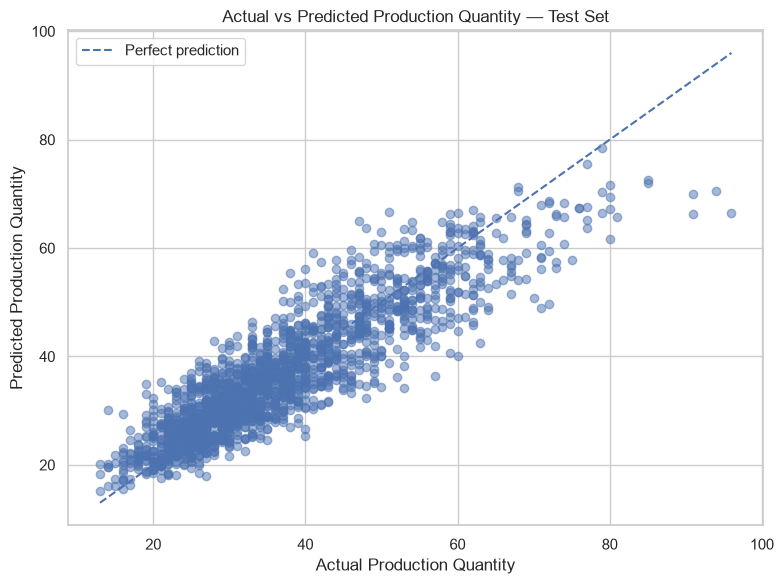

In [27]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

lower = min(float(y_test.min()), float(np.min(y_pred)))
upper = max(float(y_test.max()), float(np.max(y_pred)))

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Production Quantity")
plt.ylabel("Predicted Production Quantity")
plt.title("Actual vs Predicted Production Quantity — Test Set")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation of Actual vs Predicted Quantities

Points close to the diagonal indicate that predicted quantities are close to the corresponding observed quantities.

Points above the diagonal indicate overprediction, while points below the diagonal indicate underprediction.

The distribution of points provides a visual assessment of prediction accuracy across the range of actual production quantities. The scatter plot should be interpreted alongside the numerical evaluation metrics rather than used as the sole measure of model performance.

## 5.8 Prediction Error Analysis

Prediction errors provide additional information about the model's performance.

The residual is defined as:

**Residual = Actual Production Quantity − Predicted Production Quantity**

Residuals close to zero indicate accurate predictions. Large positive or negative residuals indicate larger prediction errors.

The residual distribution and residual plot are examined to identify potential systematic overprediction, underprediction, or patterns in the errors.

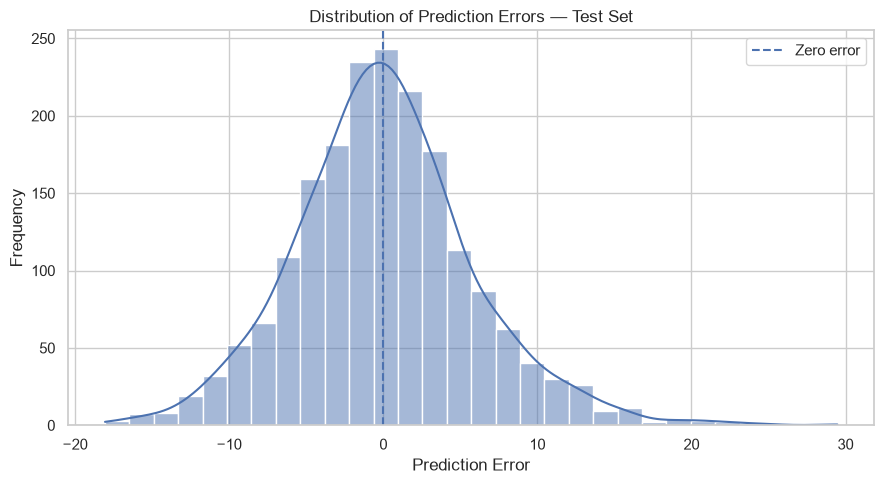

In [28]:
plt.figure(figsize=(9, 5))

sns.histplot(
    prediction_results["prediction_error"],
    bins=30,
    kde=True
)

plt.axvline(0, linestyle="--", label="Zero error")

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors — Test Set")
plt.legend()
plt.tight_layout()
plt.show()

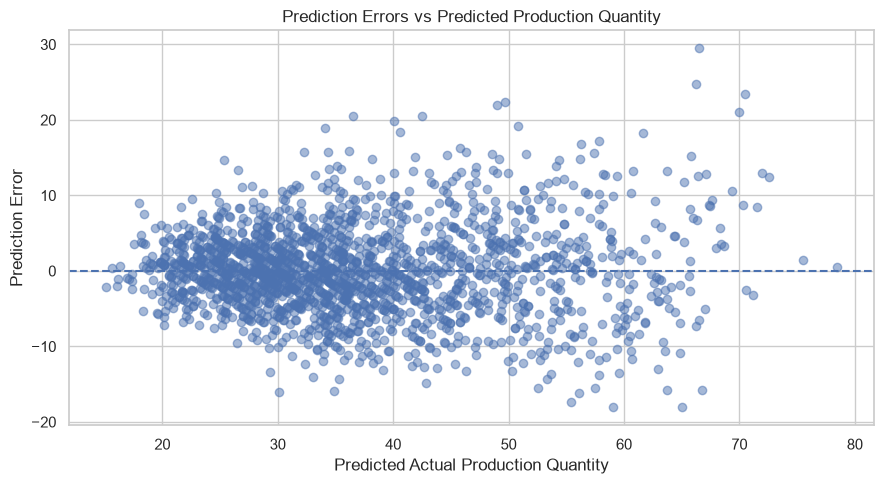

In [29]:
plt.figure(figsize=(9, 5))

plt.scatter(
    prediction_results["predicted_actual_qty"],
    prediction_results["prediction_error"],
    alpha=0.5
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Actual Production Quantity")
plt.ylabel("Prediction Error")
plt.title("Prediction Errors vs Predicted Production Quantity")
plt.tight_layout()
plt.show()

In [30]:
residual_summary = pd.DataFrame({
    "Measure": [
        "Mean prediction error",
        "Median prediction error",
        "Mean absolute error",
        "Standard deviation of prediction errors",
        "Maximum absolute error"
    ],
    "Value": [
        prediction_results["prediction_error"].mean(),
        prediction_results["prediction_error"].median(),
        prediction_results["absolute_error"].mean(),
        prediction_results["prediction_error"].std(),
        prediction_results["absolute_error"].max()
    ]
})

display(residual_summary)

,Measure,Value
0,Mean prediction error,0.060302
1,Median prediction error,-0.163881
2,Mean absolute error,4.441332
3,Standard deviation of prediction errors,5.850421
4,Maximum absolute error,29.469242


### Interpretation of Prediction Errors

A mean residual close to zero suggests limited average signed error, although it does not guarantee that individual predictions are accurate.

A residual distribution centred around zero indicates that errors occur on both sides of the predicted values. Patterns in the residual-versus-prediction plot may indicate that prediction accuracy differs across production quantities.

Large residuals highlight records for which the model's predictions differ substantially from observed production. Such records may warrant further investigation into unusual operating conditions or data quality.

## 5.9 Model Prediction Demonstration

The final five records from the held-out test dataset are displayed to demonstrate the model's predictions under different historical production conditions.

The table includes the actual production quantity, predicted quantity, prediction error, and absolute error. Where available, the item name is also shown to provide product context.

These records illustrate how the saved model can be used to estimate actual production quantity for individual observations.

In [31]:
demonstration_results = prediction_results.tail(5).copy()

# Add item name for context if it is available.
if "item_name" in test_df.columns:
    demonstration_results.insert(
        1,
        "item_name",
        test_df.loc[
            demonstration_results.index,
            "item_name"
        ].values
    )

display(
    demonstration_results.round(3)
)

C:\Users\hasnd\AppData\Local\Temp\ipykernel_19368\964025931.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  demonstration_results.round(3)


,week_start_date,item_name,actual_qty,predicted_actual_qty,prediction_error,absolute_error
9490,2026-03-30,ZURI - RED,35,41.919,-6.919,6.919
9491,2026-03-30,MUSA - BEIGE,58,53.834,4.166,4.166
9492,2026-03-30,TM 0267 - MAROON,26,24.490,1.510,1.510
9493,2026-03-30,[SAMPLE] SHOE GENTS - BLACK,38,37.735,0.265,0.265
9494,2026-03-30,TRUE MOCCACINO - L - BLACK,24,29.715,-5.715,5.715


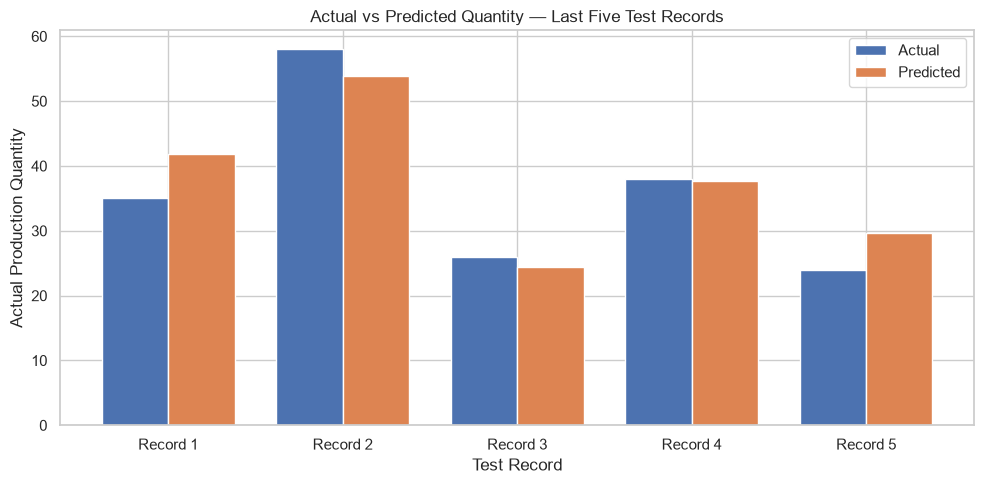

In [32]:
plot_demo = prediction_results.tail(5).copy()

x = np.arange(len(plot_demo))
width = 0.38

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    plot_demo["actual_qty"],
    width,
    label="Actual"
)

plt.bar(
    x + width / 2,
    plot_demo["predicted_actual_qty"],
    width,
    label="Predicted"
)

plt.xlabel("Test Record")
plt.ylabel("Actual Production Quantity")
plt.title("Actual vs Predicted Quantity — Last Five Test Records")
plt.xticks(x, [f"Record {i + 1}" for i in range(len(plot_demo))])
plt.legend()
plt.tight_layout()
plt.show()

## 5.10 Exporting Prediction Results

The prediction results are exported to a CSV file for documentation and further analysis.

The file contains the test-period date, observed actual production quantity, predicted quantity, prediction error, and absolute error.

These results can be reused for reporting or as inputs to the separate prescriptive analytics phase.

In [33]:
outputs_dir = project_root / "outputs"
outputs_dir.mkdir(parents=True, exist_ok=True)

prediction_output_path = (
    outputs_dir / "notebook5_test_predictions.csv"
)

prediction_results.to_csv(
    prediction_output_path,
    index=False
)

print("Prediction results exported successfully.")
print("Output file:", prediction_output_path)
print("Number of predictions:", len(prediction_results))

Prediction results exported successfully.
Output file: c:\Production-DI Leather\production-DI\outputs\notebook5_test_predictions.csv
Number of predictions: 1899


## 5.11 Final Summary

This notebook demonstrated the predictive capability of the Voting Ensemble model developed in Notebook 4.

The saved model was loaded and applied to the held-out chronological test records to predict actual production quantity (`actual_qty`). Predicted values were compared with observed quantities using R², MAE, and RMSE.

Visualisations and residual summaries were used to examine prediction accuracy and the distribution of prediction errors. A small set of test predictions was also displayed to demonstrate the model's application to individual production records.

This notebook completes the prediction demonstration for Phase 1: Predictive Analytics. The outputs provide a foundation for the separate Phase 2 prescriptive analytics component, which will investigate feasible resource combinations for approaching desired production targets.